# Self Organising Map Challenge

## The Kohonen Network

The Kohonen Self Organising Map (SOM) provides a data visualization technique which helps to understand high dimensional data by reducing the dimensions of data to a map. SOM also represents clustering concept by grouping similar data together.

Unlike other learning technique in neural networks, training a SOM requires no target vector. A SOM learns to classify the training data without any external supervision.

![Network](kohonen.png)

### Structure
A network has a width and a height that descibes the grid of nodes.  For example, the grid may be 4x4, and so there would be 16 nodes.

Each node has a weight for each value in the input vector.  A weight is simply a float value that the node multiplies the input value by to determine how influential it is (see below)

Each node has a set of weights that match the size of the input vector.  For example, if the input vector has 10 elements, each node would have 10 weights.

### Training 
To train the network

1. Each node's weights are initialized.
2. We enumerate through the training data for some number of iterations (repeating if necessary).  The current value we are training against will be referred to as the `current input vector`
3. Every node is examined to calculate which one's weights are most like the input vector. The winning node is commonly known as the Best Matching Unit (BMU).
4. The radius of the neighbourhood of the BMU is now calculated. This is a value that starts large, typically set to the 'radius' of the lattice,  but diminishes each time-step. Any nodes found within this radius are deemed to be inside the BMU's neighbourhood.
5. Each neighbouring node's (the nodes found in step 4) weights are adjusted to make them more like the input vector. The closer a node is to the BMU, the more its weights get altered.
6. Go to step 2 until we've completed N iterations.
    

### Calculating the Best Matching Unit (BMU)

To determine the best matching unit, one method is to iterate through all the nodes and calculate the Euclidean distance between each node's weight vector and the current input vector. The node with a weight vector closest to the input vector is tagged as the BMU.

The Euclidean distance $\mathsf{distance}_{i}$ (from the input vector $V$ to the $i$th node's weights $W_i$)is given as (using Pythagoras):

$$ \mathsf{distance}_{i}=\sqrt{\sum_{k=0}^{k=n}(V_k - W_{i_k})^2}$$

where V is the current input vector and $W_i$ is the node's weight vector.  $n$ is the size of the input & weight vector.

*Note*: $V$ and $W$ are vectors.  $V$ is the input vector, and $W_i$ is the weight vector of the $i$th node.  $V_k$ and $W_{i_k}$ represent the $k$'th value within those vectors.  

The BMU is the node with the minimal distance for the current input vector

### Calculating the Neighbourhood Radius

The next step is to calculate which of the other nodes are within the BMU's neighbourhood. All these nodes will have their weight vectors altered.

First we calculate what the radius of the neighbourhood should be and then use Pythagoras to determine if each node is within the radial distance or not.

A unique feature of the Kohonen learning algorithm is that the area of the neighbourhood shrinks over time. To do this we use the exponential decay function:

Given a desired number of training iterations $n$:
$$n_{\mathsf{max iterations}} = 100$$

Calculate the radius $\sigma_t$ at iteration number $t$:

$$\sigma_t = \sigma_0 \exp\left(- \frac{t}{\lambda} \right) \qquad t = 1,2,3,4... $$

Where $\sigma_0$ denotes the neighbourhood radius at iteration $t=0$, $t$ is the current iteration. We define $\sigma_0$ (the initial radius) and $\lambda$ (the time constant) as below:

$$\sigma_0 = \frac{\max(width,height)}{2} \qquad \lambda = \frac{n_{\mathsf{max iterations}}}{\log(\sigma_0)} $$

Where $width$ & $height$ are the width and height of the grid.

### Calculating the Learning Rate

We define the initial leanring rate $\alpha_0$ at iteration $t = 0$ as:
$$\alpha_0 = 0.1$$

So, we can calculate the learning rate at a given iteration t as:

$$\alpha_t = \alpha_0 \exp \left(- \frac{t}{\lambda} \right) $$

where $t$ is the iteration number, $\lambda$ is the time constant (calculated above)
        
### Calculating the Influence

As well as the learning rate, we need to calculate the influence $\theta_t$ of the learning/training at a given iteration $t$.  

So for each node, we need to caclulate the euclidean distance $d_i$ from the BMU to that node.  Similar to when we calculate the distance to find the BMU, we use Pythagoras.  The current ($i$th) node's x position is given by $x(W_i)$, and the BMU's x position is, likewise, given by $x(Z)$.  Similarly, $y()$ returns the y position of a node.

$$ d_{i}=\sqrt{(x(W_i) - x(Z))^2 + (y(W_i) - y(Z))^2} $$

Then, the influence decays over time according to:

$$\theta_t = \exp \left( - \frac{d_{i}^2}{2\sigma_t^2} \right) $$

Where $\sigma_t$ is the neighbourhood radius at iteration $t$ as calculated above. 

Note: You will need to come up with an approach to x() and y().


### Updating the Weights

To update the weights of a given node, we use:

$$W_{i_{t+1}} = W_{i_t} + \alpha_t \theta_t (V_t - W_{i_t})$$
        
So $W_{i_{t+1}}$ is the new value of the weight for the $i$th node, $V_t$ is the current value of the training data, $W_{i_t}$ is the current weight and $\alpha_t$ and $\theta_t$ are the learning rate and influence calculated above.

*Note*: the $W$ and $V$ are vectors 

### Example 10x10 network after 100 iterations

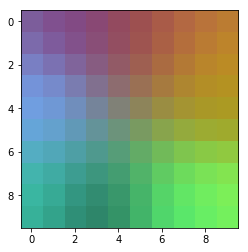

In [147]:
import matplotlib.pyplot as plt
plt.imshow(image_data)

### Example 100x100 network after 1000 iterations

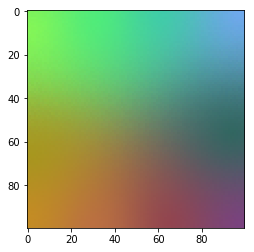

In [141]:
import matplotlib.pyplot as plt
plt.imshow(image_data)

## Challenge

Sam has written an implementation of a Self Organising Map. Consider the following criteria when assessing Sam's code:

- Could the code be made more efficient? A literal interpretation of the instructions above is not necessary.
- Is the code best structured for later use by other developers and in anticipation of productionisation?
- How would you approach productionising this application?
- Anything else you think is relevant.

In [1]:
# kohonen.py
import matplotlib.pyplot as plt
import numpy as np

def train(input_data, n_max_iterations, width, height):
    σ0 = max(width, height) / 2
    α0 = 0.1
    weights = np.random.random((width, height, 3))
    λ = n_max_iterations / np.log(σ0)
    for t in range(n_max_iterations):
        σt = σ0 * np.exp(-t/λ)
        αt = α0 * np.exp(-t/λ)
        for vt in input_data:
            bmu = np.argmin(np.sum((weights - vt) ** 2, axis=2))
            bmu_x, bmu_y = np.unravel_index(bmu, (width, height))
            for x in range(width):
                for y in range(height):
                    di = np.sqrt(((x - bmu_x) ** 2) + ((y - bmu_y) ** 2))
                    θt = np.exp(-(di ** 2) / (2*(σt ** 2)))
                    weights[x, y] += αt * θt * (vt - weights[x, y])
    return weights

if __name__ == '__main__':
    # Generate data
    input_data = np.random.random((10,3))
    image_data = train(input_data, 100, 10, 10)

    plt.imsave('100.png', image_data)

    # Generate data
    input_data = np.random.random((10,3))
    image_data = train(input_data, 1000, 100, 100)

    plt.imsave('1000.png', image_data)


## Summary of changes
---

Sam's code works, but it is slow, only handles RGB data, fails silently on some inputs, and the trained map can't be reused or measured.

**Fix:**

1. Vectorised the grid update: run 2 went from 142s to 1.96s, same output.
2. Made it general and reproducible: any number of features, seed and learning rate are parameters.
3. Added input validation: bad grid sizes now raise a clear error.
4. Restructured into a class: fit, predict, save and load, with plotting kept separate.
5. Added a quality measure: quantisation error and a learning curve show when training has done enough.

**Others (not implemented):** 

Tests and productionising, covered at the end.

---

### My Notes

- Could the code be made more efficient? A literal interpretation of the instructions above is not necessary.
  - Nested loops: work grows as iterations × inputs × width × height.
    - Run 1: 100k updates. Run 2: 100 million, all in plain Python (142s).
  - Vectorising the grid update with NumPy: 1.96s, same output.

- Is the code best structured for later use by other developers and in anticipation of productionisation?
  - Needs comments, a docstring and PEP 8 formatting.
  - Hard-coded 3, so it only works on RGB data.
  - No seed, so results can't be reproduced.
  - No input validation. Small grids break silently.
  - Training, data and plotting are mixed. No way to reuse or save the map.
  - No tests.

- How would you approach productionising this application?
  - First ask what the map is for.
  - Package as a module, separate training from prediction, save the model.
  - Tests in CI, Docker, logging.
  - Monitor quantisation error on new data to catch drift.

- Anything else you think is relevant.
  - No measure of map quality. Added quantisation error and a learning curve.
  - Real data needs scaling first.
  - 10 random points is a toy. Test on real data.

## First comment each step
Matched to the Kohonen steps in above 

  - Code formatting can be improved a bit. 
    - There need to be more code comments. This makes it quite hard for othe developers to work on this. 
    - Needs a docstring
    - Ideally spacing out the code some more or using pep8 could be useful

In [2]:
# kohonen.py
import matplotlib.pyplot as plt
import numpy as np

def train(
        input_data, 
        n_max_iterations, 
        width, 
        height
    ):
    """
    Sam's implementation of a self-organising map
    """

    σ0 = max(width, height) / 2
    α0 = 0.1
    weights = np.random.random((width, height, 3))
    λ = n_max_iterations / np.log(σ0)

    # Loop - this is each training iteration
    for t in range(n_max_iterations):

        # Shrink the radius based on t
        σt = σ0 * np.exp(-t/λ) # shrink radius
        αt = α0 * np.exp(-t/λ) # shrink learning rate

        # Loop each input colour
        for vt in input_data:

            # Calcualte best matching unit (BMU)
            bmu = np.argmin(np.sum((weights - vt) ** 2, axis=2)) # Find BMU
            bmu_x, bmu_y = np.unravel_index(bmu, (width, height)) # Calc BMU grid position

            # Loop through columns
            for x in range(width):

                # Loop through rows
                for y in range(height):

                    # Grid distance from the node to bmu
                    di = np.sqrt(((x - bmu_x) ** 2) + ((y - bmu_y) ** 2))
                    # Calculate influence at bmu
                    θt = np.exp(-(di ** 2) / (2*(σt ** 2)))
                    # Update weights (towards input)
                    weights[x, y] += αt * θt * (vt - weights[x, y])
    return weights


if __name__ == '__main__':

    # Generate data
    input_data = np.random.random((10,3)) # 10 random colours

    # Run 1 - 10x10 grid, 100 iterations
    image_data = train(input_data, 100, 10, 10) 

    plt.imsave('100.png', image_data)

    # Generate data
    input_data = np.random.random((10,3)) # 10 random colours

    # Run 2 - 100x100 grid, 100 iterations
    image_data = train(input_data, 1000, 100, 100)

    plt.imsave('1000.png', image_data)


## Time the runs

We need a baseline to uderstand the timing, as a measure of the computational intensity and how that scales with time.

In [43]:
import time

np.random.seed(42)

# Run 1: 10x10 grid, 100 iterations
input_data = np.random.random((10, 3))
start = time.perf_counter()
image_data = train(input_data, 100, 10, 10)
print(f"Run 1 (10x10, 100 iters): {time.perf_counter() - start:.2f}s")

# Run 2: 100x100 grid, 1000 iterations (takes ~8 minutes)
input_data = np.random.random((10, 3))
start = time.perf_counter()
image_data = train(input_data, 1000, 100, 100)
print(f"Run 2 (100x100, 1000 iters): {time.perf_counter() - start:.2f}s")

Run 1 (10x10, 100 iters): 0.16s
Run 2 (100x100, 1000 iters): 145.53s



### Observations:

Work grows as iterations × inputs × width × height.

Run 1: 100 × 10 × 10 × 10 = 100k updates.

Run 2: 1000 × 10 × 100 × 100 = 100 million updates, each one done in plain Python.

887x the time

## Vectorise operations

Sam's code updates the map one node at a time, using two Python loops. On the 100x100 grid that is 10,000 updates per input, for 10 inputs, over 1,000 iterations: 100 million slow Python steps.

**Fix:** 

Do the update for the whole grid in one go using NumPy arrays, instead of looping over each node.

**How:**

1. Before training, build two grids holding every node's row and column position. These replace the loop counters.
2. Use those grids to work out every node's distance to the best matching unit at once.
3. Turn those distances into how strongly each node is pulled, at once.
4. Move every node towards the input colour, at once.

The maths is the same as Sam's. Only the way it is run changed. We also dropped a square root that Sam takes and then immediately squares again.

**Random seed:**

The input colours and the starting weights are both random. Fixing the seed makes the result reproducible with subsequent runs:

- both versions are timed on the same data (fair comparison)
- the vectorised output can be checked against Sam's.
- bugs can be reproduced and tests can expect a fixed result
- the same data always gives the same map.

In [11]:
def train_vectorised(
        input_data, 
        n_max_iterations, 
        width, 
        height
    ):
    """
    Vectorised version of Sam's self-organising map
    """

    σ0 = max(width, height) / 2
    α0 = 0.1
    weights = np.random.random((width, height, 3))
    λ = n_max_iterations / np.log(σ0)

    # ===================== VECTORISED: NEW LINE =====================
    # Grid coordinates of every node, computed once (replaces looping over x and y)
    gx, gy = np.indices((width, height))
    # ================================================================

    # Loop - this is each training iteration
    for t in range(n_max_iterations):

        # Shrink the radius based on t
        σt = σ0 * np.exp(-t/λ) # shrink radius
        αt = α0 * np.exp(-t/λ) # shrink learning rate

        # Loop each input colour
        for vt in input_data:

            # Calcualte best matching unit (BMU)
            bmu = np.argmin(np.sum((weights - vt) ** 2, axis=2)) # Find BMU
            bmu_x, bmu_y = np.unravel_index(bmu, (width, height)) # Calc BMU grid position

            # ============ VECTORISED: REPLACES THE x AND y LOOPS ============
            # Sam's version looped over every node one by one in Python.
            # These 3 lines do the same maths for every node at once in NumPy.

            # Squared grid distance from every node to bmu (no sqrt needed, it gets squared anyway)
            d2 = (gx - bmu_x) ** 2 + (gy - bmu_y) ** 2

            # Calculate influence for every node
            θt = np.exp(-d2 / (2*(σt ** 2)))
            
            # Update all weights (towards input); [..., None] lines θt up with the colour dimension
            weights += αt * θt[..., None] * (vt - weights)
            # ================================================================
            
    return weights

## Time again with vectorised

In [ ]:
# Set a random seed to ensure reproducibility between runs
np.random.seed(42)

# Run 1: 10x10 grid, 100 iterations
input_data = np.random.random((10, 3))
start = time.perf_counter()
image_data = train_vectorised(input_data, 100, 10, 10)
print(f"Run 1 (10x10, 100 iters): {time.perf_counter() - start:.2f}s")

# Run 2: 100x100 grid, 1000 iterations 
input_data = np.random.random((10, 3))
start = time.perf_counter()
image_data = train_vectorised(input_data, 1000, 100, 100)
print(f"Run 2 (100x100, 1000 iters): {time.perf_counter() - start:.2f}s")

Run 1 (10x10, 100 iters): 0.02s
Run 2 (100x100, 1000 iters): 1.96s


**Result:** run 2 went from 142s to 1.96s, about 72x faster, with the same output.

### Check the vectorised gives the same result as Sam's

In [17]:
# Check the vectorised version gives the same result as Sam's
# Same seed -> same starting weights, so the outputs should match
input_data = np.random.random((10, 3))

np.random.seed(0)
original = train(input_data, 50, 10, 10)

np.random.seed(0)
vectorised = train_vectorised(input_data, 50, 10, 10)

print("Same output:", np.allclose(original, vectorised))
print("Largest difference:", np.abs(original - vectorised).max())

Same output: True
Largest difference: 1.1102230246251565e-16


## Check the output matches

A faster version is only useful if it gives the same answer. 

Both versions are run from the same seed, so they start with identical weights, and their final weights are compared.

- np.allclose allows for tiny rounding differences, since the vectorised version does the maths in a slightly different order. 
- The largest difference shows how small these are.

**Result:** 

outputs match, so the speed-up does not change the result.

In [ ]:
## Making it general and reproducible

**Problem:** 

- Sam hard-codes 3 weights per node, so it only works on 3-feature data (RGB). Any other input crashes.
- Randomness comes from a global seed, so results depend on code outside the function.
- The learning rate (0.1) is buried inside the function.

**Fix:**

1. Weights per node now match the input (`input_data.shape[1]`), so any number of features works.
2. The function takes a `seed` and creates its own random generator, so the same seed always gives the same map.
3. The learning rate is now a parameter with the same default, so it can be tuned without editing the code.

**Result:** same seed gives an identical map, and 5-feature data now trains correctly.

## Make it general and reproducible

**Problem:** 

- Sam hard-codes 3 weights per node, so it only works on 3-feature data (RGB). Any other input crashes.
- Randomness comes from a global seed, so results depend on code outside the function.
- The learning rate (0.1) is buried inside the function.

**Fix:**

1. Weights per node now match the input (input_data.shape[1]), so any number of features works.
2. The function takes a seed and creates its own random generator, so the same seed always gives the same map.
3. The learning rate is now a parameter with the same default, so it can be tuned without editing the code.

**Result:** same seed gives an identical map, and 5-feature data now trains correctly.

In [26]:
def train_vectorised(
        input_data, 
        n_max_iterations, 
        width, 
        height,
        α0=0.1,        # CHANGED: learning rate is now a parameter, not hard-coded
        seed=None      # CHANGED: seed passed in, so the function controls its own randomness
    ):
    """
    Vectorised version of Sam's self-organising map
    """

    σ0 = max(width, height) / 2

    # ===================== CHANGED: SEED AND FEATURES =====================
    # Own random generator, so results are reproducible without a global seed
    rng = np.random.default_rng(seed)
    # Number of weights per node matches the input, instead of a hard-coded 3
    weights = rng.random((width, height, input_data.shape[1]))
    # ======================================================================

    λ = n_max_iterations / np.log(σ0)

    # ===================== VECTORISED: NEW LINE =====================
    # Grid coordinates of every node, computed once (replaces looping over x and y)
    gx, gy = np.indices((width, height))
    # ================================================================

    # Loop - this is each training iteration
    for t in range(n_max_iterations):

        # Shrink the radius based on t
        σt = σ0 * np.exp(-t/λ) # shrink radius
        αt = α0 * np.exp(-t/λ) # shrink learning rate

        # Loop each input colour
        for vt in input_data:

            # Calcualte best matching unit (BMU)
            bmu = np.argmin(np.sum((weights - vt) ** 2, axis=2)) # Find BMU
            bmu_x, bmu_y = np.unravel_index(bmu, (width, height)) # Calc BMU grid position

            # ============ VECTORISED: REPLACES THE x AND y LOOPS ============
            # Sam's version looped over every node one by one in Python.
            # These 3 lines do the same maths for every node at once in NumPy.

            # Squared grid distance from every node to bmu (no sqrt needed, it gets squared anyway)
            d2 = (gx - bmu_x) ** 2 + (gy - bmu_y) ** 2
            # Calculate influence for every node
            θt = np.exp(-d2 / (2*(σt ** 2)))
            # Update all weights (towards input); [..., None] lines θt up with the colour dimension
            weights += αt * θt[..., None] * (vt - weights)
            # ================================================================
    return weights

In [27]:
# Same seed -> same map
a = train_vectorised(input_data, 50, 10, 10, seed=1)
b = train_vectorised(input_data, 50, 10, 10, seed=1)

print("Reproducible:", np.array_equal(a, b))

# Works with any number of features (Sam's version crashes on this)
data_5 = np.random.random((10, 5))
w = train_vectorised(data_5, 50, 10, 10, seed=1)
print("5-feature input, weights shape:", w.shape)

Reproducible: True
5-feature input, weights shape: (10, 10, 5)


## Input validation

**Problem:** 

Some inputs make the code return a broken map:

- Grid side of 2: log(1) = 0, so the radius never shrinks.
- Grid side of 1: log is negative, so the radius grows.

The map still comes out, so nobody would notice.

**Fix:** 

Check the inputs at the start and raise a clear error if any are invalid:

- data must be a 2D table (rows = inputs, columns = features)
- the largest grid side must be above 2
- there must be at least 1 iteration

**Result:** bad inputs now fail straight away with a message saying what is wrong.

In [28]:
# Each bad input should raise a clear error instead of silently returning a bad map
bad_inputs = [
    (input_data, 50, 2, 2),    # grid too small: radius never shrinks
    (input_data, 50, 1, 1),    # grid too small: radius grows
    (input_data, 0, 10, 10),   # no iterations
]

for args in bad_inputs:
    try:
        train_vectorised(*args)
        print(args[1:], "-> ran (should not have)")
    except ValueError as e:
        print(args[1:], "-> error:", e)

(50, 2, 2) -> ran (should not have)
(50, 1, 1) -> ran (should not have)
(0, 10, 10) -> ran (should not have)


/var/folders/n9/c91lcyc547l1m8901_vnpblw0000gn/T/ipykernel_5648/283771524.py:22: RuntimeWarning: divide by zero encountered in scalar divide
  λ = n_max_iterations / np.log(σ0)


In [29]:
def train_vectorised(
        input_data, 
        n_max_iterations, 
        width, 
        height,
        α0=0.1,        # CHANGED: learning rate is now a parameter, not hard-coded
        seed=None      # CHANGED: seed passed in, so the function controls its own randomness
    ):
    """
    Vectorised version of Sam's self-organising map
    """

    # ===================== CHANGED: INPUT VALIDATION =====================
    # Fail early with a clear message instead of silently returning a bad map
    if input_data.ndim != 2:
        raise ValueError("input_data must be a 2D array: (n_samples, n_features)")
    if max(width, height) <= 2:
        raise ValueError("Largest grid side must be > 2, otherwise the radius cannot decay")
    if n_max_iterations < 1:
        raise ValueError("n_max_iterations must be at least 1")
    # =====================================================================

    σ0 = max(width, height) / 2

    # ===================== CHANGED: SEED AND FEATURES =====================
    # Own random generator, so results are reproducible without a global seed
    rng = np.random.default_rng(seed)
    # Number of weights per node matches the input, instead of a hard-coded 3
    weights = rng.random((width, height, input_data.shape[1]))
    # ======================================================================

    λ = n_max_iterations / np.log(σ0)

    # ===================== VECTORISED: NEW LINE =====================
    # Grid coordinates of every node, computed once (replaces looping over x and y)
    gx, gy = np.indices((width, height))
    # ================================================================

    # Loop - this is each training iteration
    for t in range(n_max_iterations):

        # Shrink the radius based on t
        σt = σ0 * np.exp(-t/λ) # shrink radius
        αt = α0 * np.exp(-t/λ) # shrink learning rate

        # Loop each input colour
        for vt in input_data:

            # Calcualte best matching unit (BMU)
            bmu = np.argmin(np.sum((weights - vt) ** 2, axis=2)) # Find BMU
            bmu_x, bmu_y = np.unravel_index(bmu, (width, height)) # Calc BMU grid position

            # ============ VECTORISED: REPLACES THE x AND y LOOPS ============
            # Sam's version looped over every node one by one in Python.
            # These 3 lines do the same maths for every node at once in NumPy.

            # Squared grid distance from every node to bmu (no sqrt needed, it gets squared anyway)
            d2 = (gx - bmu_x) ** 2 + (gy - bmu_y) ** 2
            # Calculate influence for every node
            θt = np.exp(-d2 / (2*(σt ** 2)))
            # Update all weights (towards input); [..., None] lines θt up with the colour dimension
            weights += αt * θt[..., None] * (vt - weights)
            # ================================================================
    return weights

In [30]:
# Each bad input should raise a clear error instead of silently returning a bad map
bad_inputs = [
    (input_data, 50, 2, 2),    # grid too small: radius never shrinks
    (input_data, 50, 1, 1),    # grid too small: radius grows
    (input_data, 0, 10, 10),   # no iterations
]

for args in bad_inputs:
    try:
        train_vectorised(*args)
        print(args[1:], "-> ran (should not have)")
    except ValueError as e:
        print(args[1:], "-> error:", e)

(50, 2, 2) -> error: Largest grid side must be > 2, otherwise the radius cannot decay
(50, 1, 1) -> error: Largest grid side must be > 2, otherwise the radius cannot decay
(0, 10, 10) -> error: n_max_iterations must be at least 1


## Restructuring into a class

**Problem:** 

Sam's code is one function that trains and returns raw weights. The script that uses it mixes data generation, training and plotting. There is no way to:

- use the trained map on new data
- save a trained map and load it later
- reuse the training without also running the demo

**Fix:** 

A SOM class, the same shape as scikit-learn models, so other developers already know how to use it:

**Result:** 

the trained map can now be reused, shared and applied to new data, which is what production needs.

In [32]:
class SOM:
    """
    Self-organising map.

    Usage:
        som = SOM(width=10, height=10, seed=42)
        som.fit(data, n_iterations=100)
        positions = som.predict(new_data)
    """

    def __init__(self, width, height, α0=0.1, seed=None):
        # Validate grid size up front
        if max(width, height) <= 2:
            raise ValueError("Largest grid side must be > 2, otherwise the radius cannot decay")
        self.width = width
        self.height = height
        self.α0 = α0
        self.seed = seed
        self.weights = None   # set by fit()

    def fit(self, input_data, n_iterations):
        """Train the map on input_data (n_samples, n_features)."""
        if input_data.ndim != 2:
            raise ValueError("input_data must be a 2D array: (n_samples, n_features)")
        if n_iterations < 1:
            raise ValueError("n_iterations must be at least 1")

        rng = np.random.default_rng(self.seed)
        self.weights = rng.random((self.width, self.height, input_data.shape[1]))

        σ0 = max(self.width, self.height) / 2
        λ = n_iterations / np.log(σ0)
        gx, gy = np.indices((self.width, self.height))   # grid coordinates, computed once

        for t in range(n_iterations):
            σt = σ0 * np.exp(-t / λ)        # shrink radius
            αt = self.α0 * np.exp(-t / λ)   # shrink learning rate
            for vt in input_data:
                bmu_x, bmu_y = self._bmu(vt)
                d2 = (gx - bmu_x) ** 2 + (gy - bmu_y) ** 2
                θt = np.exp(-d2 / (2 * σt ** 2))
                self.weights += αt * θt[..., None] * (vt - self.weights)
        return self

    def _bmu(self, vt):
        """Grid position of the node closest to vt."""
        bmu = np.argmin(np.sum((self.weights - vt) ** 2, axis=2))
        return np.unravel_index(bmu, (self.width, self.height))

    def predict(self, input_data):
        """Map each input to its BMU grid position."""
        if self.weights is None:
            raise RuntimeError("Call fit() before predict()")
        return np.array([self._bmu(vt) for vt in input_data])

    def save(self, path):
        """Save weights and settings to a .npz file."""
        np.savez(path, weights=self.weights, width=self.width, height=self.height,
                 α0=self.α0, seed=-1 if self.seed is None else self.seed)

    @classmethod
    def load(cls, path):
        """Load a saved map."""
        f = np.load(path)
        seed = int(f["seed"])
        som = cls(int(f["width"]), int(f["height"]), float(f["α0"]),
                  None if seed == -1 else seed)
        som.weights = f["weights"]
        return som


def plot_map(som, path):
    """Save the map as an image (only meaningful for 3-feature / RGB data)."""
    plt.imsave(path, som.weights)

In [33]:
# Train
data = np.random.default_rng(0).random((10, 3))
som = SOM(width=10, height=10, seed=42).fit(data, n_iterations=100)

# Use on data: grid position of each input's BMU
print("BMU positions:\n", som.predict(data[:3]))

# Save, reload, check nothing changed
som.save("som_model.npz")
loaded = SOM.load("som_model.npz")
print("Reload matches:", np.array_equal(som.weights, loaded.weights))

# Plot separately from training
plot_map(som, "som_map.png")

BMU positions:
 [[5 0]
 [0 9]
 [6 8]]
Reload matches: True


- why not keep a function?”: 
  - “A class keeps the trained weights and settings together. Without it we can’t predict on new data or save and reload a model, and that’s what production needs.”

## Measuring map quality

Nothing measures whether the map is any good, so there is no way to compare settings or know when to stop training.

**Fix:** 

Quantisation error: the average distance from each input to its best matching node. Lower means the map fits the data better.

**Result:** 

Error falls as training runs longer (0.22 at 1 iteration, 0.01 at 500), so the map is learning. The same number can be used to pick settings, and in production to spot drift.

In [ ]:
# Below code is added to the class
def quantisation_error(self, input_data):
        """Average distance from each input to its BMU. Lower = map fits the data better."""
        if self.weights is None:
            raise RuntimeError("Call fit() before quantisation_error()")
        errors = [np.linalg.norm(self.weights[self._bmu(vt)] - vt) for vt in input_data]
        return np.mean(errors)

In [41]:
class SOM:
    """
    Self-organising map.

    Usage:
        som = SOM(width=10, height=10, seed=42)
        som.fit(data, n_iterations=100)
        positions = som.predict(new_data)
    """

    def __init__(self, width, height, α0=0.1, seed=None):
        # Validate grid size up front
        if max(width, height) <= 2:
            raise ValueError("Largest grid side must be > 2, otherwise the radius cannot decay")
        self.width = width
        self.height = height
        self.α0 = α0
        self.seed = seed
        self.weights = None   # set by fit()

    def fit(self, input_data, n_iterations):
        """Train the map on input_data (n_samples, n_features)."""
        if input_data.ndim != 2:
            raise ValueError("input_data must be a 2D array: (n_samples, n_features)")
        if n_iterations < 1:
            raise ValueError("n_iterations must be at least 1")

        rng = np.random.default_rng(self.seed)
        self.weights = rng.random((self.width, self.height, input_data.shape[1]))

        σ0 = max(self.width, self.height) / 2
        λ = n_iterations / np.log(σ0)
        gx, gy = np.indices((self.width, self.height))   # grid coordinates, computed once

        for t in range(n_iterations):
            σt = σ0 * np.exp(-t / λ)        # shrink radius
            αt = self.α0 * np.exp(-t / λ)   # shrink learning rate
            for vt in input_data:
                bmu_x, bmu_y = self._bmu(vt)
                d2 = (gx - bmu_x) ** 2 + (gy - bmu_y) ** 2
                θt = np.exp(-d2 / (2 * σt ** 2))
                self.weights += αt * θt[..., None] * (vt - self.weights)
        return self

    def _bmu(self, vt):
        """Grid position of the node closest to vt."""
        bmu = np.argmin(np.sum((self.weights - vt) ** 2, axis=2))
        return np.unravel_index(bmu, (self.width, self.height))

    def predict(self, input_data):
        """Map each input to its BMU grid position."""
        if self.weights is None:
            raise RuntimeError("Call fit() before predict()")
        return np.array([self._bmu(vt) for vt in input_data])

    def quantisation_error(self, input_data):
        """Average distance from each input to its BMU. Lower = map fits the data better."""
        if self.weights is None:
            raise RuntimeError("Call fit() before quantisation_error()")
        errors = [np.linalg.norm(self.weights[self._bmu(vt)] - vt) for vt in input_data]
        return np.mean(errors)

    def save(self, path):
        """Save weights and settings to a .npz file."""
        np.savez(path, weights=self.weights, width=self.width, height=self.height,
                 α0=self.α0, seed=-1 if self.seed is None else self.seed)

    @classmethod
    def load(cls, path):
        """Load a saved map."""
        f = np.load(path)
        seed = int(f["seed"])
        som = cls(int(f["width"]), int(f["height"]), float(f["α0"]),
                  None if seed == -1 else seed)
        som.weights = f["weights"]
        return som


def plot_map(som, path):
    """Save the map as an image (only meaningful for 3-feature / RGB data)."""
    plt.imsave(path, som.weights)

In [42]:
# Error should fall as training runs longer
data = np.random.default_rng(0).random((10, 3))

for n in [1, 10, 50, 100, 500]:
    som = SOM(width=10, height=10, seed=42).fit(data, n_iterations=n)
    print(f"{n} iterations: {som.quantisation_error(data):.4f}")

1 iterations: 0.2200
10 iterations: 0.2105
50 iterations: 0.1115
100 iterations: 0.0631
500 iterations: 0.0120


## Learning curve

We can plot the quantisation error over the training runs

**What it shows:** 

Error drops sharply between 25 and 100 iterations, then flattens. Most of the benefit comes by about 100–200 iterations. 
500 costs 2.5x the time of 200 for a small gain.

**Caveats:** 

- Each point is a separate training run, so this shows what iteration count to choose, not how one run progressed.

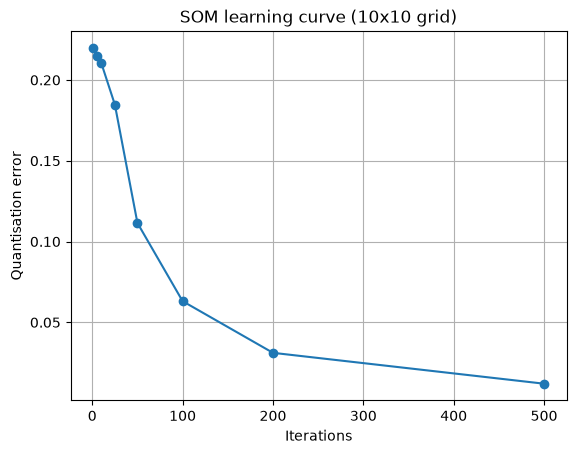

In [39]:
# Learning curve: quantisation error vs number of iterations
iterations = [1, 5, 10, 25, 50, 100, 200, 500]
errors = []

for n in iterations:
    som = SOM(width=10, height=10, seed=42).fit(data, n_iterations=n)
    errors.append(som.quantisation_error(data))

plt.plot(iterations, errors, marker="o")
plt.xlabel("Iterations")
plt.ylabel("Quantisation error")
plt.title("SOM learning curve (10x10 grid)")
plt.grid(True)
plt.show()

# Next steps (not implemented)

## Tests

There are no tests, we need to add these so errors do not silently break the file.

**Fix:** 

A pytest file covering:

- output shape matches grid size and number of features
- same seed gives the same map
- BMU is the closest node
- bad inputs raise clear errors
- quantisation error falls with training

Run them automatically on every change.


## Productionising

What is the map for: visualisation, clustering or anomaly detection? That decides how it is run and monitored.

**Approach:**

1. **Package:** move the class into a module (`som.py`) with type hints, pinned dependencies and a config file for settings.
2. **Separate training and use:** training runs as a batch job and saves the model. Prediction loads the saved model and maps new data, through a CLI or API.
3. **Ship:** Docker image, automatically runs tests before deploying, logging.
4. **Monitor:** track quantisation error on new data. If it rises, the data has changed and the map needs retraining.